# SkillBridge by Zequa
## Day 4 - Exploratory Data Analysis

### Objective
Perform exploratory data analysis on integrated ESCO
and O*NET occupation and skill datasets.

### Analysis Areas
1. Occupation Distribution Analysis
2. Skill Distribution Analysis
3. Most Common Skills
4. Occupation-Skill Relationship Analysis
5. ESCO vs O*NET Comparison
6. Career and Industry Patterns
7. Statistical Analysis
8. Data Visualization

### Expected Outcome
Identify important occupation and skill patterns to
support future NLP, Machine Learning and career
recommendation systems.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Project paths
PROJECT_ROOT = Path.cwd().parent

PROCESSED_DATA_PATH = (
    PROJECT_ROOT / "data" / "processed"
)

EDA_OUTPUT_PATH = (
    PROCESSED_DATA_PATH / "eda"
)

EDA_OUTPUT_PATH.mkdir(
    parents=True,
    exist_ok=True
)

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("SkillBridge Day 4 EDA Environment Ready!")
print("Python Version:", sys.version)
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)
print("Project Root:", PROJECT_ROOT)
print("EDA Output:", EDA_OUTPUT_PATH)

SkillBridge Day 4 EDA Environment Ready!
Python Version: 3.12.10 (v3.12.10:0cc81280367, Apr  8 2025, 08:47:00) [Clang 13.0.0 (clang-1300.0.29.30)]
Pandas Version: 2.2.3
NumPy Version: 1.26.4
Project Root: /Users/rizwansalim/Desktop/SkillBridgeByZequa
EDA Output: /Users/rizwansalim/Desktop/SkillBridgeByZequa/data/processed/eda


In [2]:
# Load unified datasets

unified_occupations = pd.read_csv(
    PROCESSED_DATA_PATH / "unified_occupations.csv"
)

unified_skills = pd.read_csv(
    PROCESSED_DATA_PATH / "unified_skills.csv"
)

esco_relationships = pd.read_csv(
    PROCESSED_DATA_PATH /
    "esco_occupation_skill_relationships.csv"
)

onet_relationships = pd.read_csv(
    PROCESSED_DATA_PATH /
    "onet_occupation_skill_relationships.csv"
)

onet_job_titles = pd.read_csv(
    PROCESSED_DATA_PATH /
    "normalized_onet_job_titles.csv"
)

# Display dataset information

datasets = {
    "Unified Occupations": unified_occupations,
    "Unified Skills": unified_skills,
    "ESCO Relationships": esco_relationships,
    "O*NET Relationships": onet_relationships,
    "O*NET Job Titles": onet_job_titles
}

for name, df in datasets.items():
    print("\n", name)
    print("Records:", len(df))
    print("Columns:", len(df.columns))
    print("Column names:", df.columns.tolist())


 Unified Occupations
Records: 4055
Columns: 3
Column names: ['Occupation ID', 'Occupation Name', 'Source']

 Unified Skills
Records: 13949
Columns: 3
Column names: ['Skill ID', 'Skill Name', 'Source']

 ESCO Relationships
Records: 126051
Columns: 6
Column names: ['occupationUri', 'occupationLabel', 'relationType', 'skillType', 'skillUri', 'skillLabel']

 O*NET Relationships
Records: 18200
Columns: 7
Column names: ['Occupation ID', 'Occupation Name', 'Skill ID', 'Skill Name', 'Measurement ID', 'Measurement Name', 'Skill Rating']

 O*NET Job Titles
Records: 54269
Columns: 6
Column names: ['O*NET-SOC Code', 'Title', 'Job Title', 'Short Title', 'Source(s)', 'Normalized Job Title']


In [3]:
# Occupation distribution by source

occupation_distribution = (
    unified_occupations
    .groupby("Source")
    .agg(
        Total_Occupations=("Occupation ID", "count"),
        Unique_Titles=("Occupation Name", "nunique")
    )
    .reset_index()
)

display(occupation_distribution)

print(
    "Total occupation records:",
    len(unified_occupations)
)

,Source,Total_Occupations,Unique_Titles
0,ESCO,3039,3039
1,O*NET,1016,1016


Total occupation records: 4055


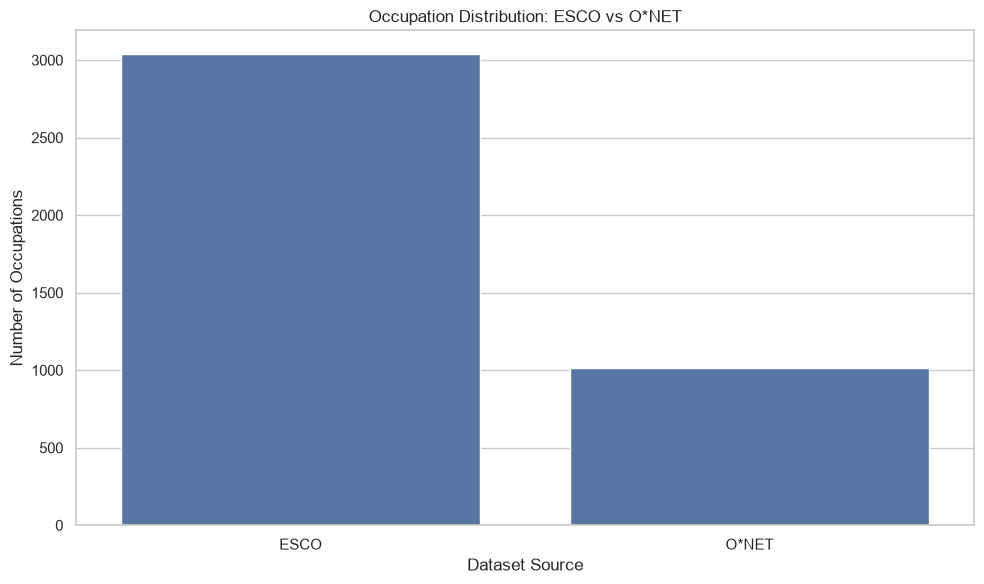

In [4]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=occupation_distribution,
    x="Source",
    y="Total_Occupations"
)

plt.title("Occupation Distribution: ESCO vs O*NET")
plt.xlabel("Dataset Source")
plt.ylabel("Number of Occupations")

plt.tight_layout()
plt.show()

In [5]:
total_occupations = occupation_distribution[
    "Total_Occupations"
].sum()

occupation_distribution["Percentage"] = (
    occupation_distribution["Total_Occupations"]
    / total_occupations * 100
).round(2)

display(occupation_distribution)

,Source,Total_Occupations,Unique_Titles,Percentage
0,ESCO,3039,3039,74.94
1,O*NET,1016,1016,25.06


In [6]:
occupation_distribution.to_csv(
    EDA_OUTPUT_PATH / "occupation_distribution.csv",
    index=False
)

print("Occupation distribution analysis saved!")

Occupation distribution analysis saved!


In [7]:
skill_distribution = (
    unified_skills
    .groupby("Source")
    .agg(
        Total_Skill_Records=("Skill ID", "count"),
        Unique_Skill_Names=("Skill Name", "nunique")
    )
    .reset_index()
)

display(skill_distribution)

print(
    "Total unified skill records:",
    len(unified_skills)
)

,Source,Total_Skill_Records,Unique_Skill_Names
0,ESCO,13939,13939
1,O*NET,10,10


Total unified skill records: 13949


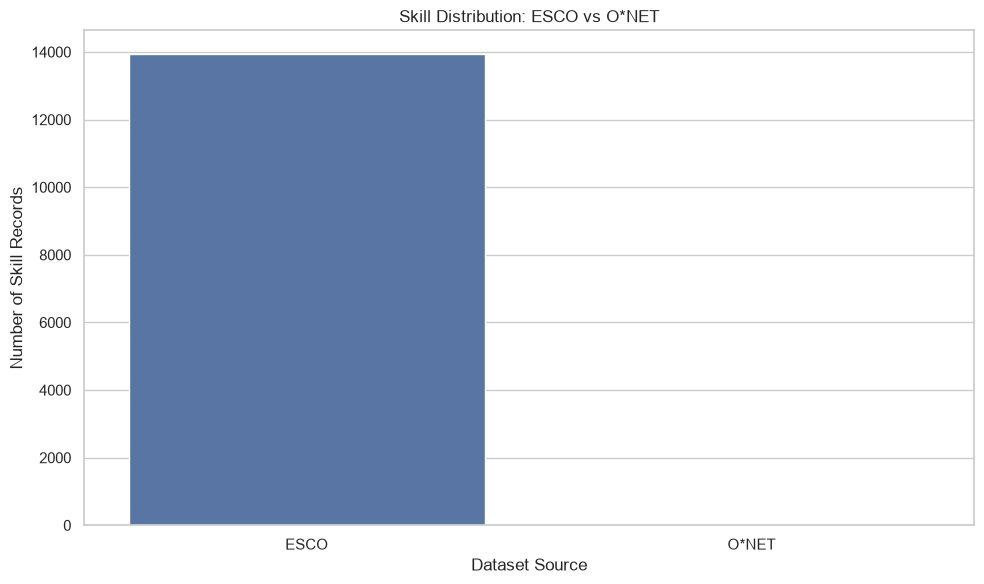

In [8]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=skill_distribution,
    x="Source",
    y="Total_Skill_Records"
)

plt.title("Skill Distribution: ESCO vs O*NET")
plt.xlabel("Dataset Source")
plt.ylabel("Number of Skill Records")

plt.tight_layout()
plt.show()

In [9]:
total_skills = skill_distribution[
    "Total_Skill_Records"
].sum()

skill_distribution["Percentage"] = (
    skill_distribution["Total_Skill_Records"]
    / total_skills * 100
).round(2)

display(skill_distribution)

,Source,Total_Skill_Records,Unique_Skill_Names,Percentage
0,ESCO,13939,13939,99.93
1,O*NET,10,10,0.07


In [10]:
unified_skills["Skill_Name_Length"] = (
    unified_skills["Skill Name"].str.len()
)

display(
    unified_skills.groupby("Source")[
        "Skill_Name_Length"
    ].describe().round(2)
)

,count,mean,std,min,25%,50%,75%,max
Source,,,,,,,,
ESCO,13939.0,27.24,11.15,1.0,19.0,26.0,33.00,87.0
O*NET,10.0,13.10,5.15,7.0,8.5,13.0,16.75,21.0


In [11]:
skill_distribution.to_csv(
    EDA_OUTPUT_PATH / "skill_distribution.csv",
    index=False
)

print("Skill distribution analysis saved successfully!")

Skill distribution analysis saved successfully!


In [12]:
esco_top_skills = (
    esco_relationships
    .groupby("skillLabel")
    .agg(
        Occupation_Count=("occupationUri", "nunique"),
        Skill_ID=("skillUri", "first")
    )
    .reset_index()
    .sort_values("Occupation_Count", ascending=False)
)

esco_top_20 = esco_top_skills.head(20)

display(esco_top_20)

,skillLabel,Occupation_Count,Skill_ID
12930,use different communication channels,340,http://data.europa.eu/esco/skill/415abd43-e8e5...
3133,create solutions to problems,339,http://data.europa.eu/esco/skill/03b9b491-fc9b...
7453,manage staff,334,http://data.europa.eu/esco/skill/339ac029-066a...
6379,keep records of work progress,321,http://data.europa.eu/esco/skill/ccfbdaad-b91d...
7120,manage budgets,319,http://data.europa.eu/esco/skill/21c5790c-0930...
5470,have computer literacy,318,http://data.europa.eu/esco/skill/d15ce60f-ddab...
10605,quality standards,313,http://data.europa.eu/esco/skill/8d4271ca-c9fd...
12632,troubleshoot,300,http://data.europa.eu/esco/skill/334e3e49-fb02...
11631,speak different languages,278,http://data.europa.eu/esco/skill/2de4572a-4724...
5635,identify customer's needs,261,http://data.europa.eu/esco/skill/68698869-c13c...


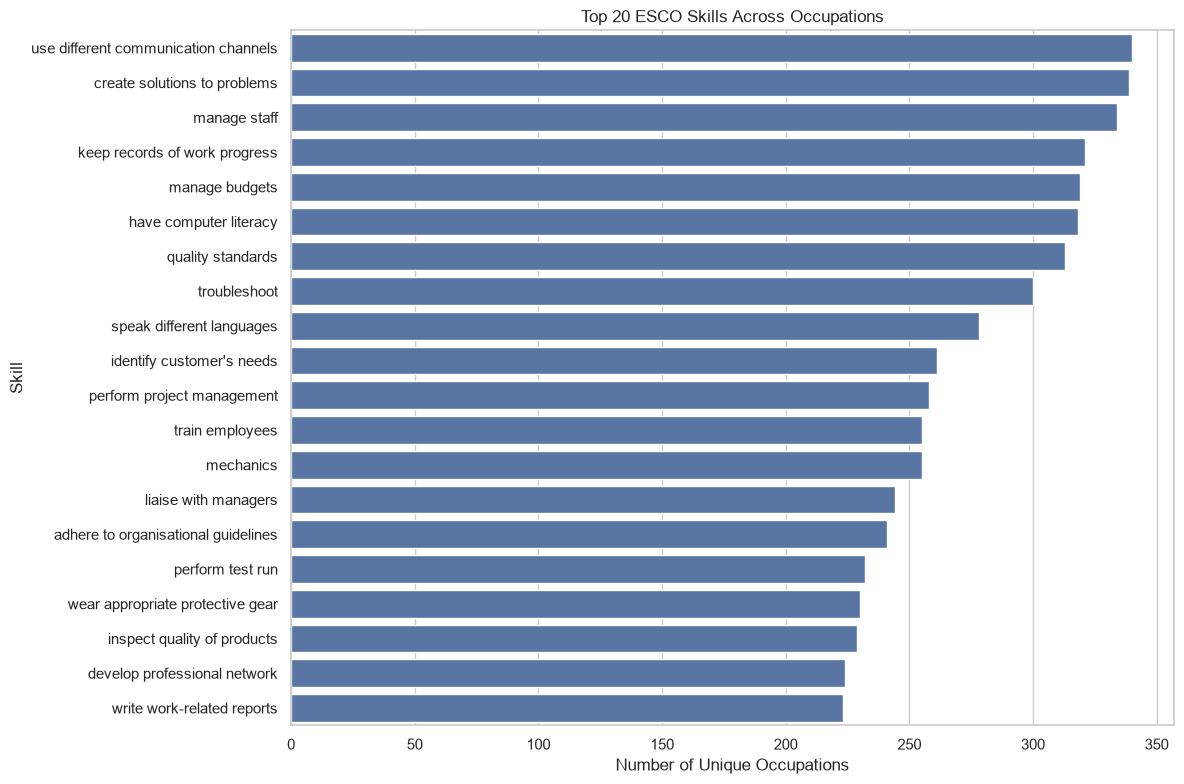

In [13]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=esco_top_20,
    x="Occupation_Count",
    y="skillLabel"
)

plt.title("Top 20 ESCO Skills Across Occupations")
plt.xlabel("Number of Unique Occupations")
plt.ylabel("Skill")
plt.tight_layout()
plt.show()

In [14]:
esco_top_20.to_csv(
    EDA_OUTPUT_PATH / "esco_top_20_skills.csv",
    index=False
)

print("ESCO top skills analysis saved successfully!")

ESCO top skills analysis saved successfully!


In [15]:
esco_top_skills = (
    esco_relationships
    .groupby("skillLabel")
    .agg(
        Occupation_Count=("occupationUri", "nunique"),
        Skill_ID=("skillUri", "first")
    )
    .reset_index()
    .sort_values("Occupation_Count", ascending=False)
    .head(20)
)

display(esco_top_skills)

,skillLabel,Occupation_Count,Skill_ID
12930,use different communication channels,340,http://data.europa.eu/esco/skill/415abd43-e8e5...
3133,create solutions to problems,339,http://data.europa.eu/esco/skill/03b9b491-fc9b...
7453,manage staff,334,http://data.europa.eu/esco/skill/339ac029-066a...
6379,keep records of work progress,321,http://data.europa.eu/esco/skill/ccfbdaad-b91d...
7120,manage budgets,319,http://data.europa.eu/esco/skill/21c5790c-0930...
5470,have computer literacy,318,http://data.europa.eu/esco/skill/d15ce60f-ddab...
10605,quality standards,313,http://data.europa.eu/esco/skill/8d4271ca-c9fd...
12632,troubleshoot,300,http://data.europa.eu/esco/skill/334e3e49-fb02...
11631,speak different languages,278,http://data.europa.eu/esco/skill/2de4572a-4724...
5635,identify customer's needs,261,http://data.europa.eu/esco/skill/68698869-c13c...


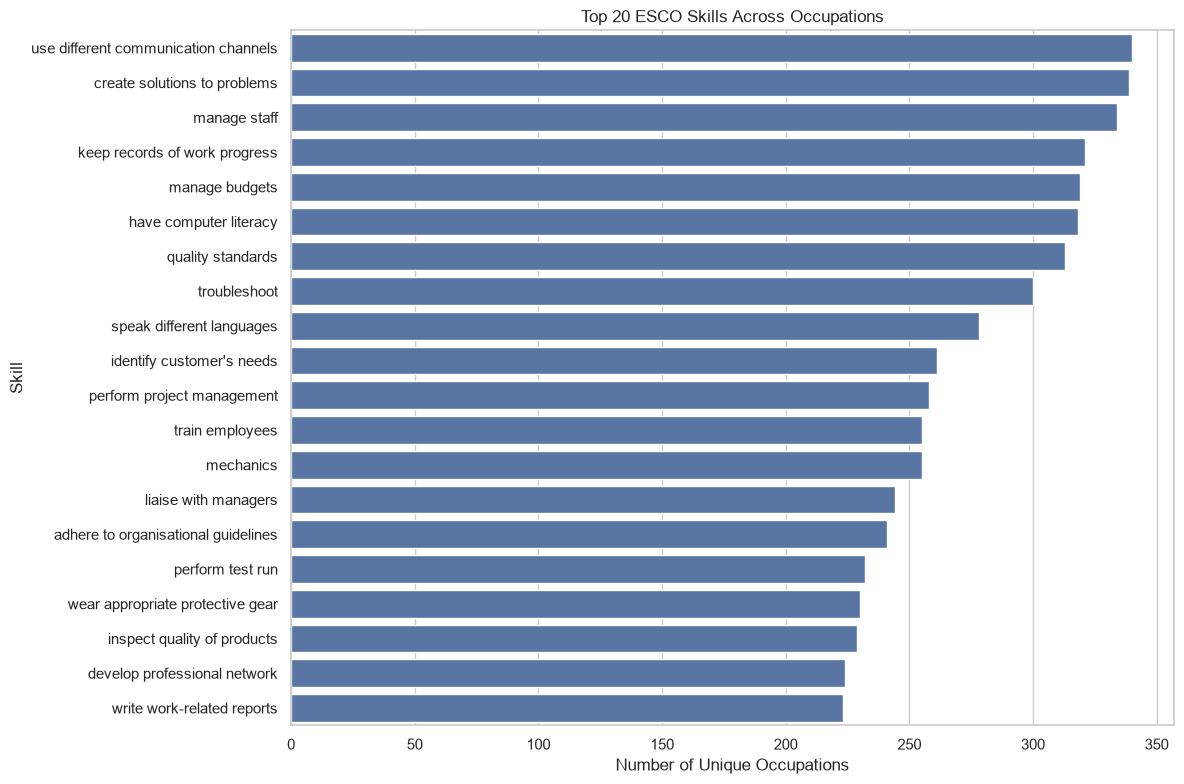

In [16]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=esco_top_skills,
    x="Occupation_Count",
    y="skillLabel"
)

plt.title("Top 20 ESCO Skills Across Occupations")
plt.xlabel("Number of Unique Occupations")
plt.ylabel("Skill")
plt.tight_layout()
plt.show()

In [17]:
esco_top_skills.to_csv(
    EDA_OUTPUT_PATH / "top_20_esco_skills.csv",
    index=False
)

print("Top 20 ESCO skills saved successfully!")

Top 20 ESCO skills saved successfully!


In [18]:
print("O*NET columns:")
print(onet_relationships.columns.tolist())

display(onet_relationships.head())

O*NET columns:
['Occupation ID', 'Occupation Name', 'Skill ID', 'Skill Name', 'Measurement ID', 'Measurement Name', 'Skill Rating']


,Occupation ID,Occupation Name,Skill ID,Skill Name,Measurement ID,Measurement Name,Skill Rating
0,11-1011.00,Chief Executives,2.A.1.a,Reading Comprehension,IM,Importance,4.12
1,11-1011.00,Chief Executives,2.A.1.a,Reading Comprehension,LV,Level,4.62
2,11-1011.00,Chief Executives,2.A.1.b,Active Listening,IM,Importance,4.00
3,11-1011.00,Chief Executives,2.A.1.b,Active Listening,LV,Level,4.75
4,11-1011.00,Chief Executives,2.A.1.c,Writing,IM,Importance,4.12


In [19]:
onet_top_skills = (
    onet_relationships
    .groupby("Skill Name")
    .agg(
        Occupation_Count=("Occupation ID", "nunique"),
        Skill_ID=("Skill ID", "first")
    )
    .reset_index()
    .sort_values("Occupation_Count", ascending=False)
    .head(20)
)

display(onet_top_skills)

,Skill Name,Occupation_Count,Skill_ID
0,Active Learning,910,2.A.2.b
1,Active Listening,910,2.A.1.b
2,Critical Thinking,910,2.A.2.a
3,Learning Strategies,910,2.A.2.c
4,Mathematics,910,2.A.1.e
5,Monitoring,910,2.A.2.d
6,Reading Comprehension,910,2.A.1.a
7,Science,910,2.A.1.f
8,Speaking,910,2.A.1.d
9,Writing,910,2.A.1.c


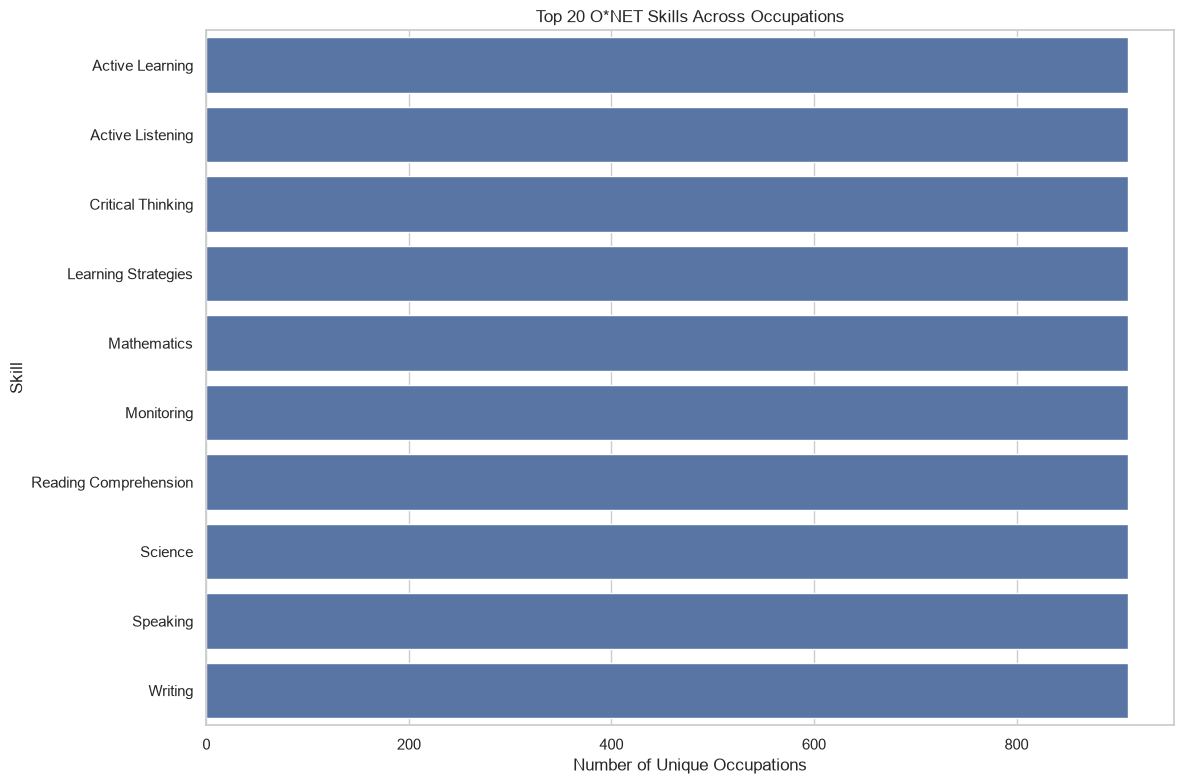

In [20]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=onet_top_skills,
    x="Occupation_Count",
    y="Skill Name"
)

plt.title("Top 20 O*NET Skills Across Occupations")
plt.xlabel("Number of Unique Occupations")
plt.ylabel("Skill")
plt.tight_layout()
plt.show()

In [21]:
onet_top_skills.to_csv(
    EDA_OUTPUT_PATH / "top_20_onet_skills.csv",
    index=False
)

print("Top 20 O*NET skills saved successfully!")

Top 20 O*NET skills saved successfully!


In [22]:
esco_occupation_skill_count = (
    esco_relationships
    .groupby(["occupationUri", "occupationLabel"])
    .agg(
        Total_Skills=("skillUri", "nunique")
    )
    .reset_index()
    .sort_values("Total_Skills", ascending=False)
)

display(esco_occupation_skill_count.head(20))

,occupationUri,occupationLabel,Total_Skills
1924,http://data.europa.eu/esco/occupation/9b889f07...,specialised doctor,178
1151,http://data.europa.eu/esco/occupation/5c082067...,computer numerical control machine operator,158
2393,http://data.europa.eu/esco/occupation/c3b82711...,computer science lecturer,140
935,http://data.europa.eu/esco/occupation/4b709f9e...,food technologist,139
1112,http://data.europa.eu/esco/occupation/5979893a...,powertrain engineer,137
153,http://data.europa.eu/esco/occupation/0bf5d25a...,medicine lecturer,133
1800,http://data.europa.eu/esco/occupation/92bb3d8c...,computer hardware engineer,132
587,http://data.europa.eu/esco/occupation/2e8820ba...,biomedical scientist,127
1492,http://data.europa.eu/esco/occupation/77abfaec...,electromechanical engineer,122
928,http://data.europa.eu/esco/occupation/4b05bef2...,social worker,121


In [23]:
onet_occupation_skill_count = (
    onet_relationships
    .groupby(["Occupation ID", "Occupation Name"])
    .agg(
        Total_Skills=("Skill ID", "nunique")
    )
    .reset_index()
    .sort_values("Total_Skills", ascending=False)
)

display(onet_occupation_skill_count.head(20))

,Occupation ID,Occupation Name,Total_Skills
0,11-1011.00,Chief Executives,10
625,43-9061.00,"Office Clerks, General",10
599,43-4141.00,New Accounts Clerks,10
600,43-4151.00,Order Clerks,10
601,43-4161.00,"Human Resources Assistants, Except Payroll and...",10
602,43-4171.00,Receptionists and Information Clerks,10
603,43-4181.00,Reservation and Transportation Ticket Agents a...,10
604,43-5011.00,Cargo and Freight Agents,10
605,43-5011.01,Freight Forwarders,10
606,43-5021.00,Couriers and Messengers,10


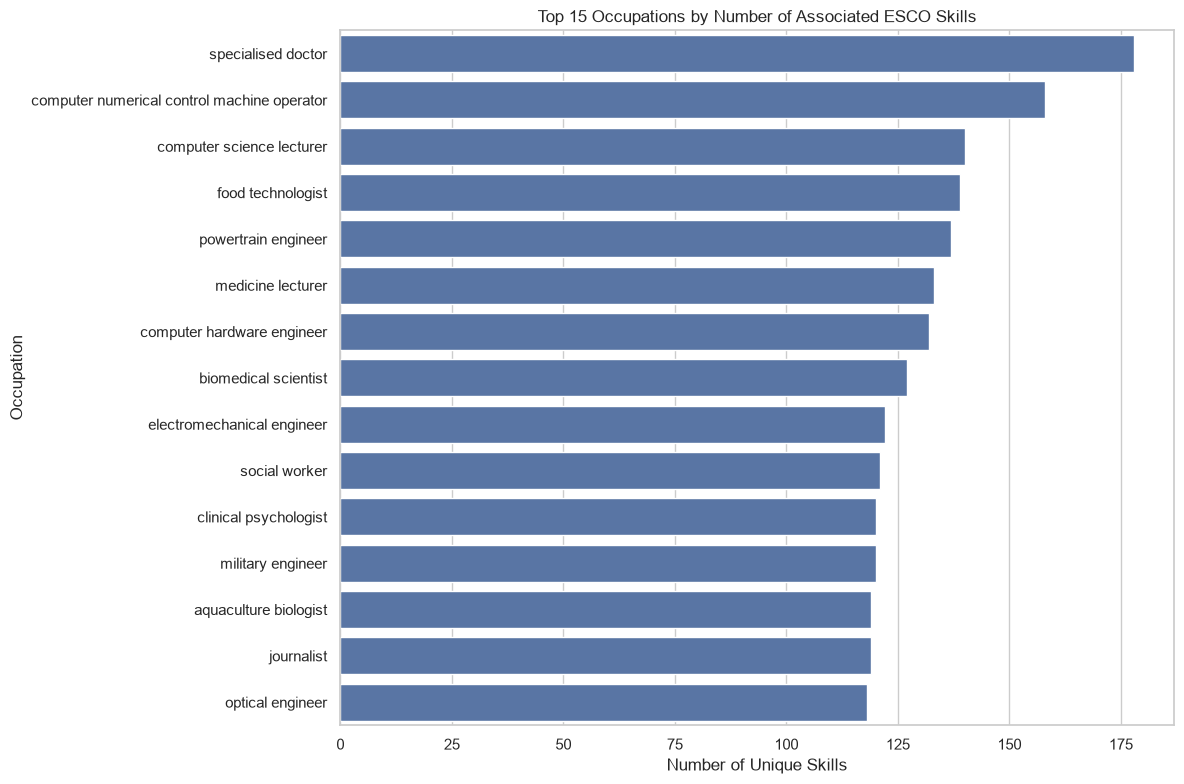

In [24]:
plt.figure(figsize=(12, 8))

top_esco_occupations = esco_occupation_skill_count.head(15)

sns.barplot(
    data=top_esco_occupations,
    x="Total_Skills",
    y="occupationLabel"
)

plt.title("Top 15 Occupations by Number of Associated ESCO Skills")
plt.xlabel("Number of Unique Skills")
plt.ylabel("Occupation")
plt.tight_layout()
plt.show()

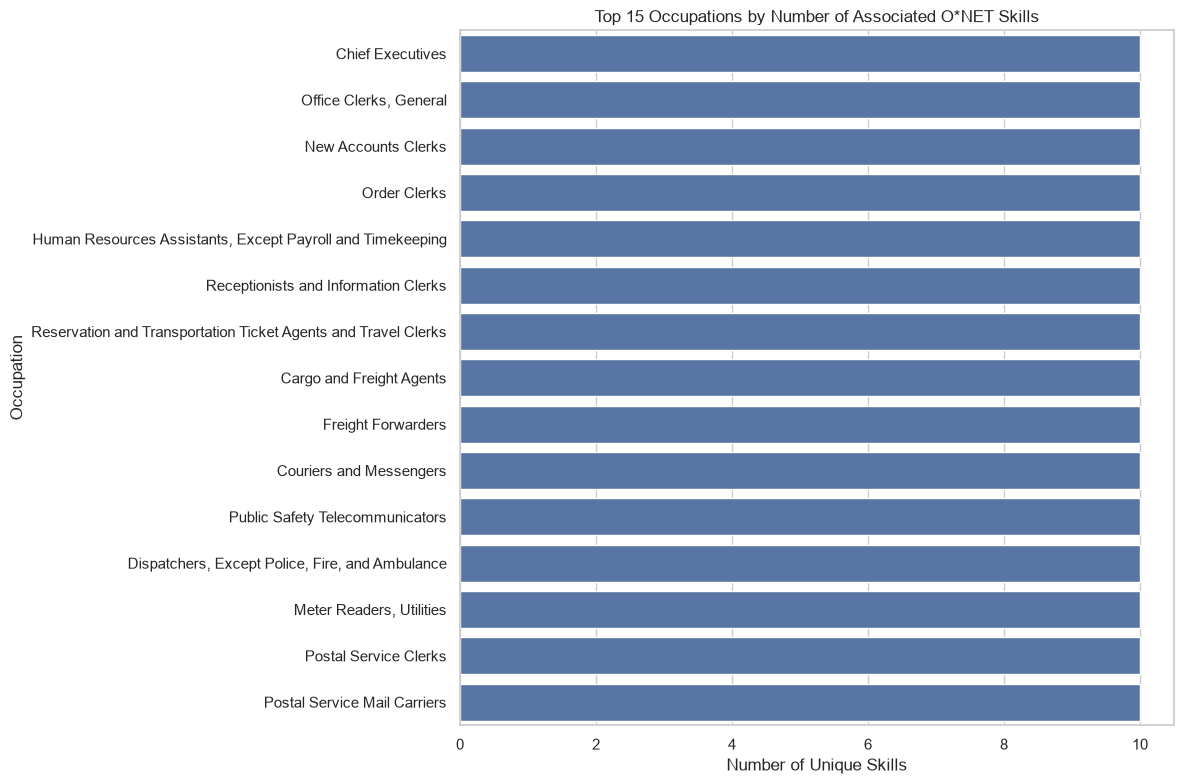

In [25]:
plt.figure(figsize=(12, 8))

top_onet_occupations = onet_occupation_skill_count.head(15)

sns.barplot(
    data=top_onet_occupations,
    x="Total_Skills",
    y="Occupation Name"
)

plt.title("Top 15 Occupations by Number of Associated O*NET Skills")
plt.xlabel("Number of Unique Skills")
plt.ylabel("Occupation")
plt.tight_layout()
plt.show()

In [26]:
esco_occupation_skill_count.to_csv(
    EDA_OUTPUT_PATH / "esco_occupation_skill_count.csv",
    index=False
)

onet_occupation_skill_count.to_csv(
    EDA_OUTPUT_PATH / "onet_occupation_skill_count.csv",
    index=False
)

print("Occupation-skill relationship analysis saved successfully!")

Occupation-skill relationship analysis saved successfully!


In [27]:
esco_occupation_total = unified_occupations[
    unified_occupations["Source"].str.contains("ESCO", case=False, na=False)
].shape[0]

onet_occupation_total = unified_occupations[
    unified_occupations["Source"].str.contains("O*NET", case=False, na=False, regex=False)
].shape[0]

occupation_comparison = pd.DataFrame({
    "Dataset": ["ESCO", "O*NET"],
    "Total_Occupations": [
        esco_occupation_total,
        onet_occupation_total
    ]
})

display(occupation_comparison)

,Dataset,Total_Occupations
0,ESCO,3039
1,O*NET,1016


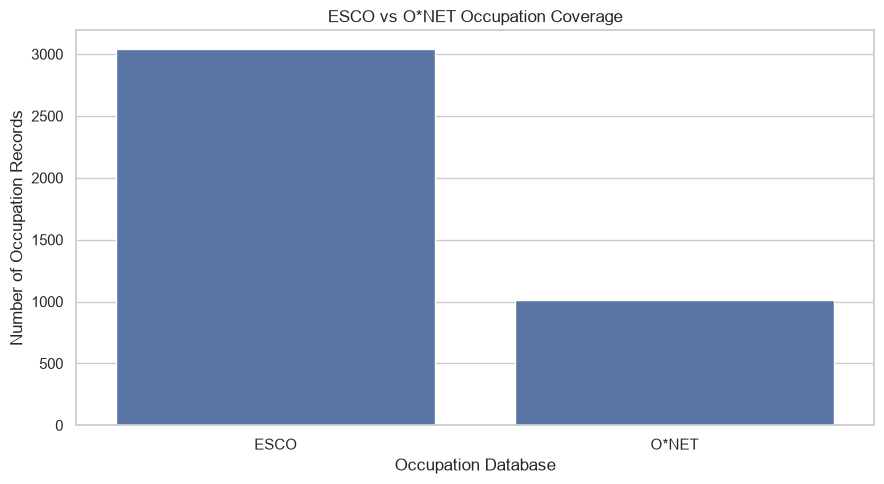

In [28]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=occupation_comparison,
    x="Dataset",
    y="Total_Occupations"
)

plt.title("ESCO vs O*NET Occupation Coverage")
plt.xlabel("Occupation Database")
plt.ylabel("Number of Occupation Records")
plt.tight_layout()
plt.show()

In [29]:
skill_comparison = (
    unified_skills
    .groupby("Source")
    .agg(
        Total_Skills=("Skill ID", "count"),
        Unique_Skill_Names=("Skill Name", "nunique")
    )
    .reset_index()
)

display(skill_comparison)

,Source,Total_Skills,Unique_Skill_Names
0,ESCO,13939,13939
1,O*NET,10,10


In [30]:
occupation_comparison.to_csv(
    EDA_OUTPUT_PATH / "occupation_database_comparison.csv",
    index=False
)

skill_comparison.to_csv(
    EDA_OUTPUT_PATH / "skill_database_comparison.csv",
    index=False
)

print("ESCO vs O*NET comparison reports saved successfully!")

ESCO vs O*NET comparison reports saved successfully!


In [31]:
career_data = pd.read_csv(
    PROJECT_ROOT / "data" / "raw" / "job_roles.csv"
)

display(career_data.head())
print("Total career roles:", len(career_data))
print("Total industries:", career_data["industry"].nunique())

,role,industry,level,required_skills
0,Data Scientist,Data Science,Entry,Python|SQL|Statistics|Machine Learning|Pandas
1,Data Analyst,Data Science,Entry,SQL|Excel|Python|Power BI|Statistics
2,Machine Learning Engineer,AI & ML,Entry,Python|Deep Learning|PyTorch|Machine Learning|SQL
3,AI Engineer,AI & ML,Entry,Python|LLM|RAG|Deep Learning|NLP
4,NLP Engineer,AI & ML,Entry,Python|NLP|Transformers|PyTorch|Hugging Face


Total career roles: 40
Total industries: 16


In [32]:
industry_distribution = (
    career_data
    .groupby("industry")
    .agg(
        Total_Roles=("role", "count"),
        Unique_Roles=("role", "nunique")
    )
    .reset_index()
    .sort_values("Total_Roles", ascending=False)
)

display(industry_distribution)

,industry,Total_Roles,Unique_Roles
15,Software & IT,6,6
1,Banking & Finance,5,5
0,AI & ML,4,4
2,Business,4,4
8,Engineering,3,3
5,Data Science,2,2
6,Design,2,2
7,Education,2,2
9,Healthcare,2,2
11,Human Resources,2,2


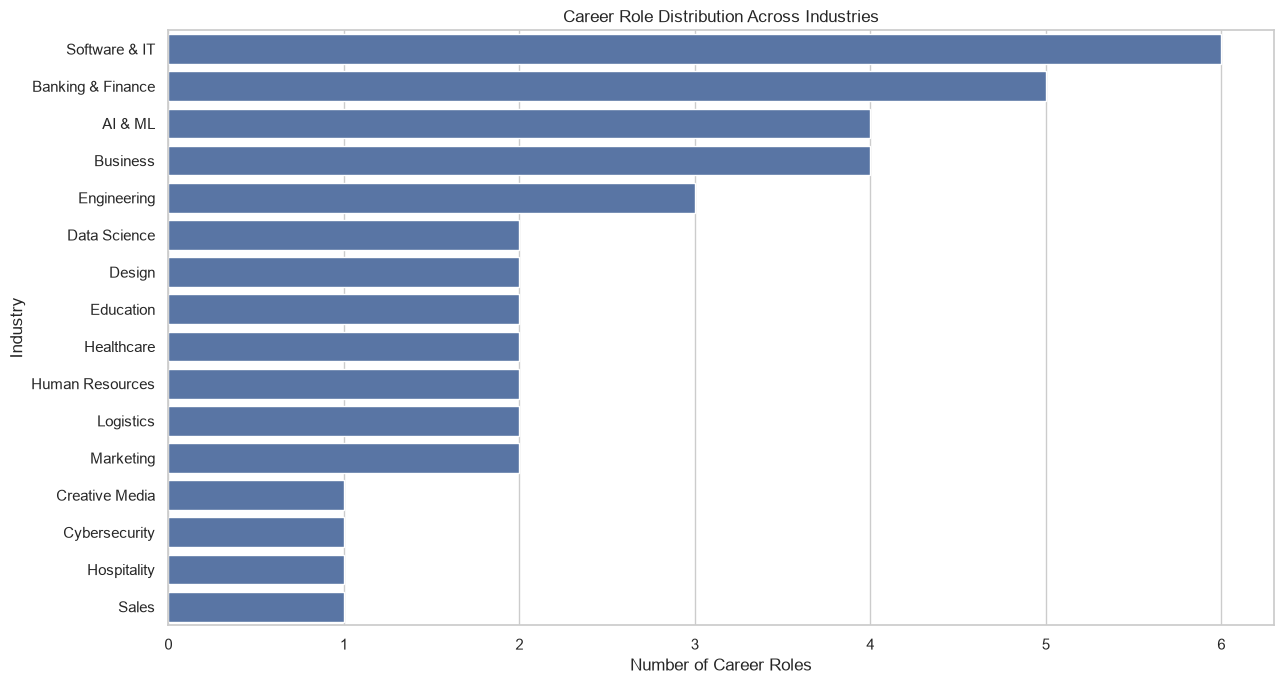

In [33]:
plt.figure(figsize=(13, 7))

sns.barplot(
    data=industry_distribution,
    x="Total_Roles",
    y="industry"
)

plt.title("Career Role Distribution Across Industries")
plt.xlabel("Number of Career Roles")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()

In [34]:
industry_skill_records = []

for _, row in career_data.iterrows():
    skills = str(row["required_skills"]).split("|")

    for skill in skills:
        if skill.strip():
            industry_skill_records.append({
                "Industry": row["industry"],
                "Role": row["role"],
                "Skill": skill.strip()
            })

industry_skills = pd.DataFrame(industry_skill_records)

industry_skill_summary = (
    industry_skills
    .groupby("Industry")
    .agg(
        Total_Skill_Associations=("Skill", "count"),
        Unique_Skills=("Skill", "nunique")
    )
    .reset_index()
    .sort_values("Unique_Skills", ascending=False)
)

display(industry_skill_summary)

,Industry,Total_Skill_Associations,Unique_Skills
15,Software & IT,30,20
1,Banking & Finance,23,14
2,Business,17,13
0,AI & ML,20,12
8,Engineering,12,11
6,Design,9,9
12,Logistics,8,8
5,Data Science,10,7
7,Education,8,7
9,Healthcare,7,7


In [35]:
industry_distribution.to_csv(
    EDA_OUTPUT_PATH / "industry_distribution.csv",
    index=False
)

industry_skill_summary.to_csv(
    EDA_OUTPUT_PATH / "industry_skill_summary.csv",
    index=False
)

industry_skills.to_csv(
    EDA_OUTPUT_PATH / "industry_skill_details.csv",
    index=False
)

print("Industry and career pattern analysis saved successfully!")

Industry and career pattern analysis saved successfully!


In [36]:
esco_statistics = esco_occupation_skill_count["Total_Skills"].describe()

print("ESCO OCCUPATION SKILL STATISTICS")
display(esco_statistics)

ESCO OCCUPATION SKILL STATISTICS


count    3039.000000
mean       41.477789
std        20.216995
min         7.000000
25%        28.000000
50%        37.000000
75%        49.000000
max       178.000000
Name: Total_Skills, dtype: float64

In [37]:
onet_statistics = onet_occupation_skill_count["Total_Skills"].describe()

print("O*NET OCCUPATION SKILL STATISTICS")
display(onet_statistics)

O*NET OCCUPATION SKILL STATISTICS


count    910.0
mean      10.0
std        0.0
min       10.0
25%       10.0
50%       10.0
75%       10.0
max       10.0
Name: Total_Skills, dtype: float64

In [38]:
statistical_comparison = pd.DataFrame({
    "ESCO": esco_occupation_skill_count["Total_Skills"].describe(),
    "O*NET": onet_occupation_skill_count["Total_Skills"].describe()
})

display(statistical_comparison.round(2))

,ESCO,O*NET
count,3039.00,910.0
mean,41.48,10.0
std,20.22,0.0
min,7.00,10.0
25%,28.00,10.0
50%,37.00,10.0
75%,49.00,10.0
max,178.00,10.0


In [39]:
print("ESCO relationship statistics")
print("Total relationships:", len(esco_relationships))
print(
    "Unique occupations:",
    esco_relationships["occupationUri"].nunique()
)
print(
    "Unique skills:",
    esco_relationships["skillUri"].nunique()
)

print("\nO*NET relationship statistics")
print("Total relationships:", len(onet_relationships))
print(
    "Unique occupations:",
    onet_relationships["Occupation ID"].nunique()
)
print(
    "Unique skills:",
    onet_relationships["Skill ID"].nunique()
)

ESCO relationship statistics
Total relationships: 126051
Unique occupations: 3039
Unique skills: 13475

O*NET relationship statistics
Total relationships: 18200
Unique occupations: 910
Unique skills: 10


In [40]:
statistical_comparison.to_csv(
    EDA_OUTPUT_PATH / "occupation_skill_statistics.csv"
)

print("Statistical analysis saved successfully!")

Statistical analysis saved successfully!


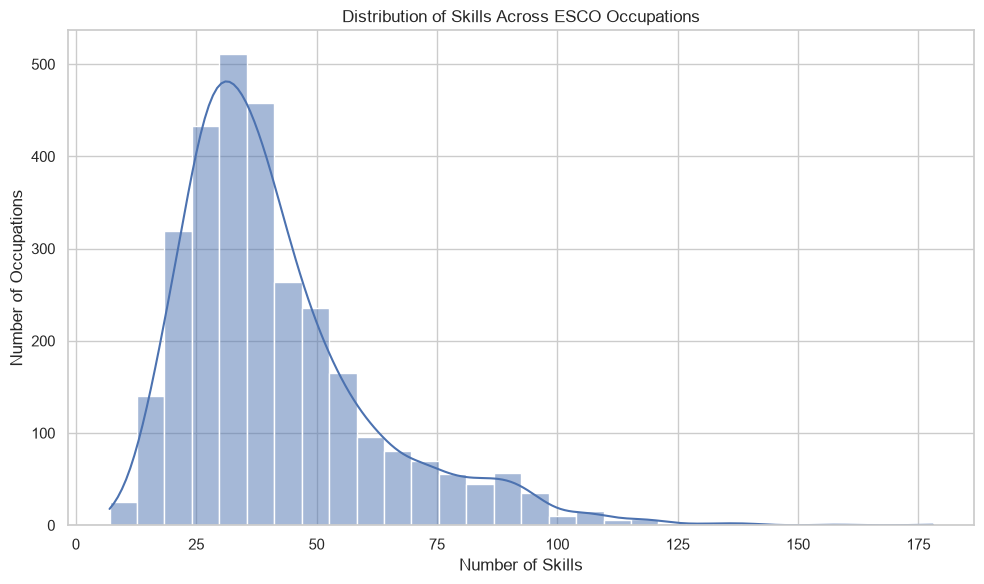

In [41]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=esco_occupation_skill_count,
    x="Total_Skills",
    bins=30,
    kde=True
)

plt.title("Distribution of Skills Across ESCO Occupations")
plt.xlabel("Number of Skills")
plt.ylabel("Number of Occupations")
plt.tight_layout()
plt.show()

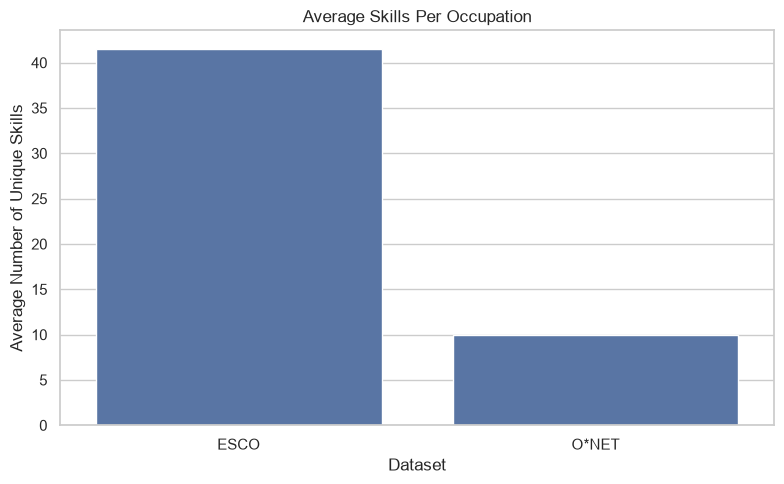

In [42]:
comparison_plot = pd.DataFrame({
    "Dataset": ["ESCO", "O*NET"],
    "Average_Skills": [
        esco_occupation_skill_count["Total_Skills"].mean(),
        onet_occupation_skill_count["Total_Skills"].mean()
    ]
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison_plot,
    x="Dataset",
    y="Average_Skills"
)

plt.title("Average Skills Per Occupation")
plt.ylabel("Average Number of Unique Skills")
plt.tight_layout()
plt.show()

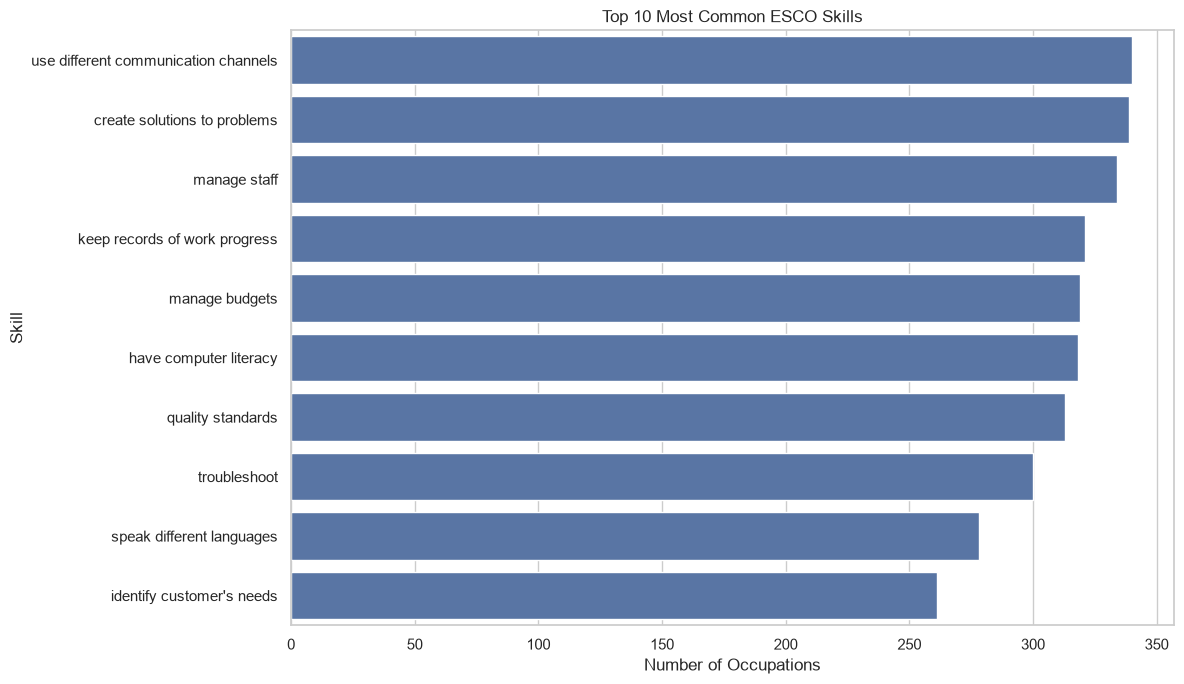

In [43]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=esco_top_skills.head(10),
    x="Occupation_Count",
    y="skillLabel"
)

plt.title("Top 10 Most Common ESCO Skills")
plt.xlabel("Number of Occupations")
plt.ylabel("Skill")
plt.tight_layout()
plt.show()

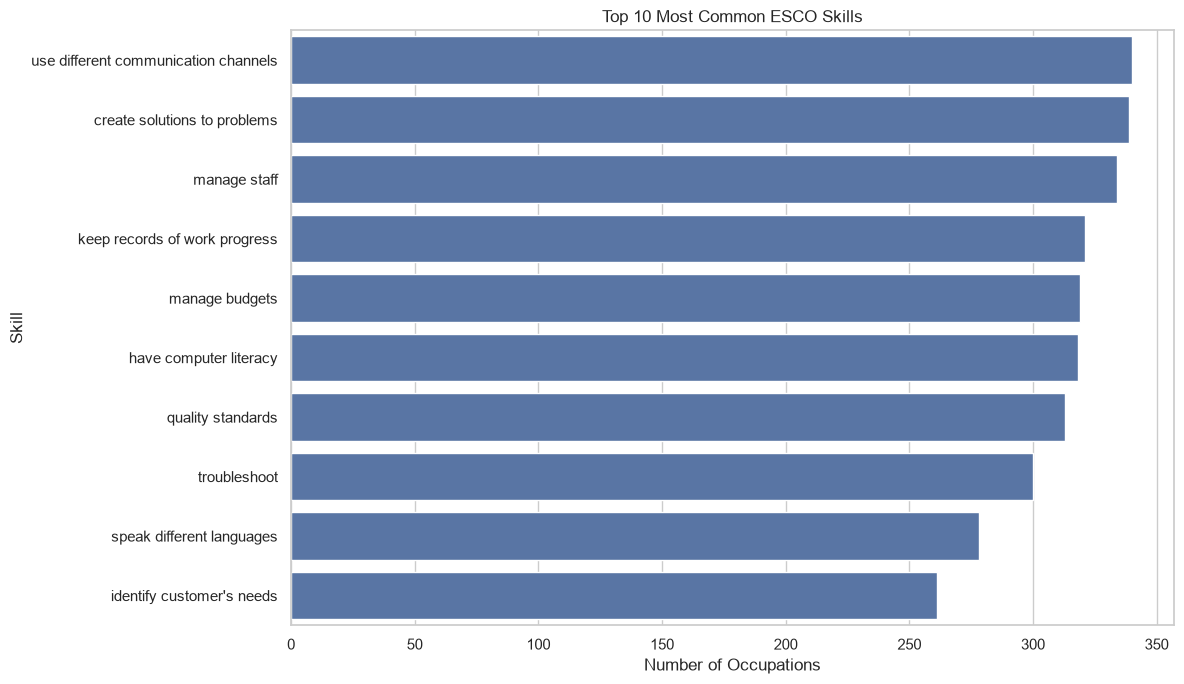

In [44]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=esco_top_skills.head(10),
    x="Occupation_Count",
    y="skillLabel"
)

plt.title("Top 10 Most Common ESCO Skills")
plt.xlabel("Number of Occupations")
plt.ylabel("Skill")
plt.tight_layout()
plt.show()

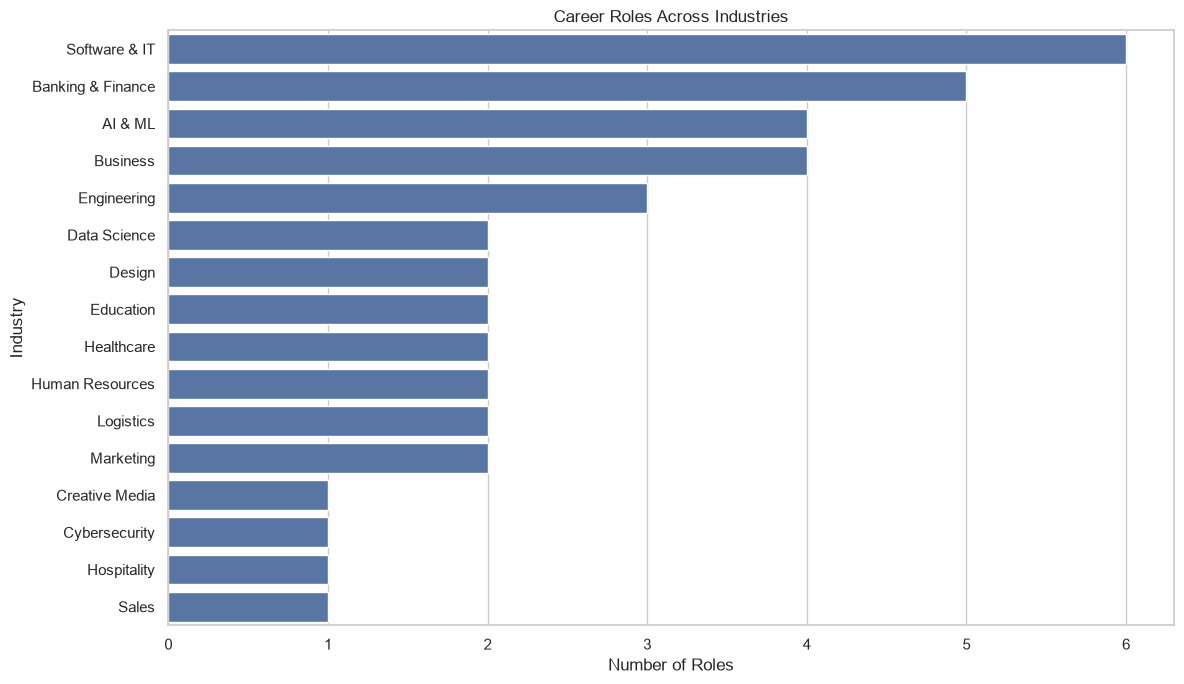

In [45]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=industry_distribution,
    x="Total_Roles",
    y="industry"
)

plt.title("Career Roles Across Industries")
plt.xlabel("Number of Roles")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()

In [46]:
chart_outputs = {
    "occupation_skill_distribution.png": 1,
    "average_skills_comparison.png": 2,
    "top_10_esco_skills.png": 3,
    "industry_distribution.png": 4
}

# Recreate and save each chart individually.
plt.figure(figsize=(10, 6))
sns.histplot(data=esco_occupation_skill_count, x="Total_Skills", bins=30, kde=True)
plt.title("Distribution of Skills Across ESCO Occupations")
plt.tight_layout()
plt.savefig(EDA_OUTPUT_PATH / "occupation_skill_distribution.png", dpi=300, bbox_inches="tight")
plt.close()

plt.figure(figsize=(8, 5))
sns.barplot(data=comparison_plot, x="Dataset", y="Average_Skills")
plt.title("Average Skills Per Occupation")
plt.tight_layout()
plt.savefig(EDA_OUTPUT_PATH / "average_skills_comparison.png", dpi=300, bbox_inches="tight")
plt.close()

plt.figure(figsize=(12, 7))
sns.barplot(data=esco_top_skills.head(10), x="Occupation_Count", y="skillLabel")
plt.title("Top 10 Most Common ESCO Skills")
plt.tight_layout()
plt.savefig(EDA_OUTPUT_PATH / "top_10_esco_skills.png", dpi=300, bbox_inches="tight")
plt.close()

plt.figure(figsize=(12, 7))
sns.barplot(data=industry_distribution, x="Total_Roles", y="industry")
plt.title("Career Roles Across Industries")
plt.tight_layout()
plt.savefig(EDA_OUTPUT_PATH / "industry_distribution.png", dpi=300, bbox_inches="tight")
plt.close()

print("All EDA charts saved successfully!")
print("Output folder:", EDA_OUTPUT_PATH)

All EDA charts saved successfully!
Output folder: /Users/rizwansalim/Desktop/SkillBridgeByZequa/data/processed/eda


In [47]:
from datetime import datetime

report = f"""
=========================================================
             SKILLBRIDGE AI
       DAY 4 - EXPLORATORY DATA ANALYSIS
=========================================================

Generated: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}

1. DATASET OVERVIEW
---------------------------------------------------------

Unified Occupations: {len(unified_occupations)}
Unified Skills: {len(unified_skills)}

ESCO Relationships: {len(esco_relationships)}
O*NET Relationships: {len(onet_relationships)}

O*NET Job Titles: {len(onet_job_titles)}

2. OCCUPATION COVERAGE
---------------------------------------------------------

ESCO Occupations: {esco_occupation_total}
O*NET Occupations: {onet_occupation_total}

3. SKILL COVERAGE
---------------------------------------------------------

ESCO Unique Skills: {
    unified_skills[unified_skills["Source"].str.contains("ESCO", case=False, na=False)]
    ["Skill Name"].nunique()
}

O*NET Unique Skills: {
    unified_skills[unified_skills["Source"].str.contains("O*NET", case=False, na=False)]
    ["Skill Name"].nunique()
}

4. TOP ESCO SKILLS
---------------------------------------------------------

{esco_top_skills.head(10).to_string(index=False)}

5. TOP O*NET SKILLS
---------------------------------------------------------

{onet_top_skills.head(10).to_string(index=False)}

6. INDUSTRY DISTRIBUTION
---------------------------------------------------------

{industry_distribution.to_string(index=False)}

7. OCCUPATION SKILL STATISTICS
---------------------------------------------------------

{statistical_comparison.round(2).to_string()}

8. OUTPUT LOCATION
---------------------------------------------------------

{EDA_OUTPUT_PATH}

=========================================================
                 END OF REPORT
=========================================================
"""

report_path = EDA_OUTPUT_PATH / "day4_eda_report.txt"

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report)

print(report)
print("\nReport saved:", report_path)


             SKILLBRIDGE AI
       DAY 4 - EXPLORATORY DATA ANALYSIS

Generated: 2026-11-17 21:20:13

1. DATASET OVERVIEW
---------------------------------------------------------

Unified Occupations: 4055
Unified Skills: 13949

ESCO Relationships: 126051
O*NET Relationships: 18200

O*NET Job Titles: 54269

2. OCCUPATION COVERAGE
---------------------------------------------------------

ESCO Occupations: 3039
O*NET Occupations: 1016

3. SKILL COVERAGE
---------------------------------------------------------

ESCO Unique Skills: 13939

O*NET Unique Skills: 10

4. TOP ESCO SKILLS
---------------------------------------------------------

                          skillLabel  Occupation_Count                                                              Skill_ID
use different communication channels               340 http://data.europa.eu/esco/skill/415abd43-e8e5-4643-b5da-5f11307af57a
        create solutions to problems               339 http://data.europa.eu/esco/skill/03b9b491-fc9b-

In [48]:
print("DAY 4 OUTPUT VALIDATION")
print("=" * 50)

for file in sorted(EDA_OUTPUT_PATH.iterdir()):
    if file.is_file():
        print(f"{file.name:<45} {file.stat().st_size:,} bytes")

print("=" * 50)
print("Total output files:", len(list(EDA_OUTPUT_PATH.iterdir())))

DAY 4 OUTPUT VALIDATION
average_skills_comparison.png                 65,436 bytes
day4_eda_report.txt                           4,189 bytes
esco_occupation_skill_count.csv               311,197 bytes
esco_top_20_skills.csv                        1,991 bytes
industry_distribution.csv                     283 bytes
industry_distribution.png                     145,675 bytes
industry_skill_details.csv                    7,160 bytes
industry_skill_summary.csv                    308 bytes
occupation_database_comparison.csv            47 bytes
occupation_distribution.csv                   93 bytes
occupation_skill_distribution.png             127,791 bytes
occupation_skill_statistics.csv               157 bytes
onet_occupation_skill_count.csv               44,460 bytes
skill_database_comparison.csv                 68 bytes
skill_distribution.csv                        97 bytes
top_10_esco_skills.png                        147,931 bytes
top_20_esco_skills.csv                        1,991 byte

In [49]:
from pathlib import Path

required_files = [
    "occupation_distribution.csv",
    "skill_distribution.csv",
    "top_20_esco_skills.csv",
    "top_20_onet_skills.csv",
    "esco_occupation_skill_count.csv",
    "onet_occupation_skill_count.csv",
    "occupation_database_comparison.csv",
    "skill_database_comparison.csv",
    "industry_distribution.csv",
    "industry_skill_summary.csv",
    "industry_skill_details.csv",
    "occupation_skill_statistics.csv",
    "day4_eda_report.txt",
    "occupation_skill_distribution.png",
    "average_skills_comparison.png",
    "top_10_esco_skills.png",
    "industry_distribution.png"
]

missing_files = [
    name for name in required_files
    if not (EDA_OUTPUT_PATH / name).exists()
]

print("DAY 4 FINAL VALIDATION")
print("=" * 45)
print("Expected files:", len(required_files))
print("Generated files:", len(required_files) - len(missing_files))

if missing_files:
    print("\nMissing files:")
    for name in missing_files:
        print("-", name)
else:
    print("\nSUCCESS: All expected Day 4 outputs exist!")

DAY 4 FINAL VALIDATION
Expected files: 17
Generated files: 17

SUCCESS: All expected Day 4 outputs exist!
